Arquivo não encontrado: dados baixados da API.
Semanas sem clima, interpoladas: 13
574 semanas, de 2015-01-04 a 2025-12-28
    data_iniSE      SE   ano  se  casos_est  casos        Rt     pop    tempmed    tempmin    tempmax    umidmed    umidmin    umidmax
571 2025-12-14  202551  2025  51      410.0    410  0.912182  725419  20.766143  17.984557  24.683371  83.973657  69.404843  94.338300
572 2025-12-21  202552  2025  52      338.0    338  0.778329  725419  24.805871  19.638000  29.882400  68.115871  46.234857  87.177643
573 2025-12-28  202553  2025  53      418.0    418  1.039045  725419  24.901543  21.024700  29.560771  76.609157  55.320686  93.373471
{'2015/16': 52, '2016/17': 52, '2017/18': 52, '2018/19': 52, '2019/20': 52, '2020/21': 53, '2021/22': 52, '2022/23': 52, '2023/24': 52, '2024/25': 52}
temporada  SE_pico  data_pico  sem_pico  casos_no_pico  total_casos  temp_no_pico  umid_no_pico
  2015/16       13 2016-03-27        25           1269        20429          21.4         

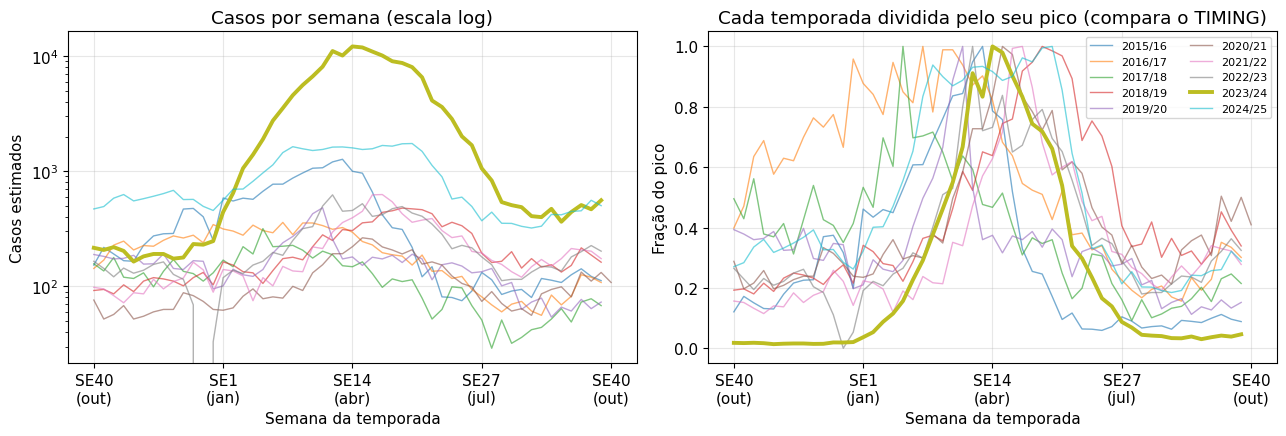

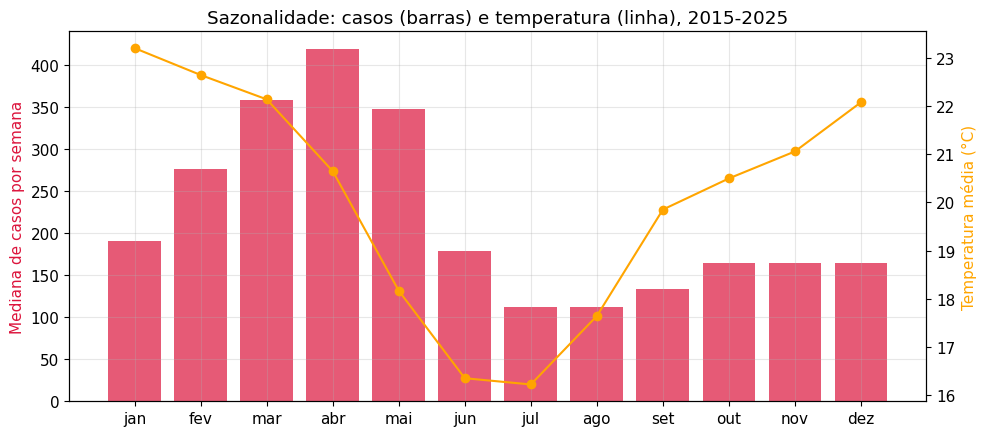

Mês mais quente: jan | mês com maior mediana de casos: abr
tempmed: maior correlação = 0.37 com defasagem de 7 semanas
umidmed: maior correlação = 0.09 com defasagem de 1 semanas


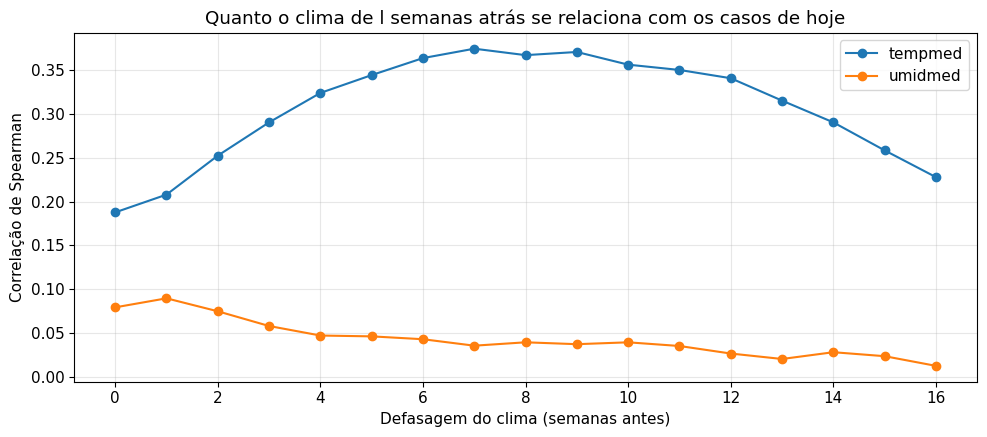

Janela: de 6 a 8 semanas antes do pico

temporada  temp_pre_pico  umid_pre_pico  temp_temporada  umid_temporada
  2015/16           24.5           72.5            19.2            82.7
  2016/17           22.0           88.9            18.0            88.0
  2017/18           20.5           82.5            19.0            83.4
  2018/19           20.7           92.8            18.9            87.7
  2019/20           23.1           74.0            20.4            74.3
  2020/21           22.8           74.9            21.1            69.3
  2021/22           25.0           68.3            20.3            70.1
  2022/23           22.0           90.4            20.4            79.6
  2023/24           22.7           81.5            20.9            75.7
  2024/25           21.4           83.3            19.7            77.9

Média (10 temporadas):
 temp_pre_pico     22.5
umid_pre_pico     80.9
temp_temporada    19.8
umid_temporada    78.9
      h     erro Euler       erro RK4
      1      

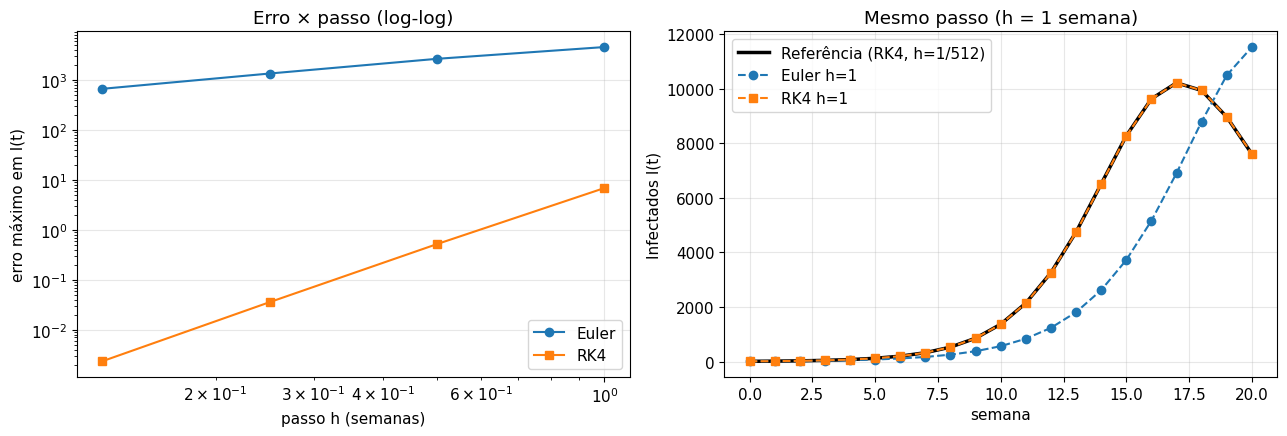

Total exato S(0)-S(T) = 57,437.9

     h      retângulo       erro       trapézio       erro
     1       55,409.2    2028.77       57,346.4      91.50
   0.5       56,446.4     991.49       57,415.1      22.86
  0.25       56,947.9     490.03       57,432.2       5.71
Bisseção: pico em t = 15.901 semanas (18 iterações)  |  máximo direto na malha: 15.90 semanas
         beta  gamma   rho    R0    R2  pico_obs (sem)  pico_modelo (sem)  total_obs  total_modelo  erro_pico (sem)
2015/16  0.44   0.25  0.04  1.76  0.80              25              21.17    20429.0      21109.23             -3.8
2016/17  0.41   0.25  0.02  1.65  0.66              19              19.19    10589.0       9187.08              0.2
2017/18  0.38   0.25  0.01  1.52  0.66              17              18.37     6395.0       5972.74              1.4
2018/19  0.37   0.25  0.03  1.48  0.73              31              30.85    11043.0      11081.92             -0.1
2019/20  0.36   0.25  0.02  1.42  0.34              23  

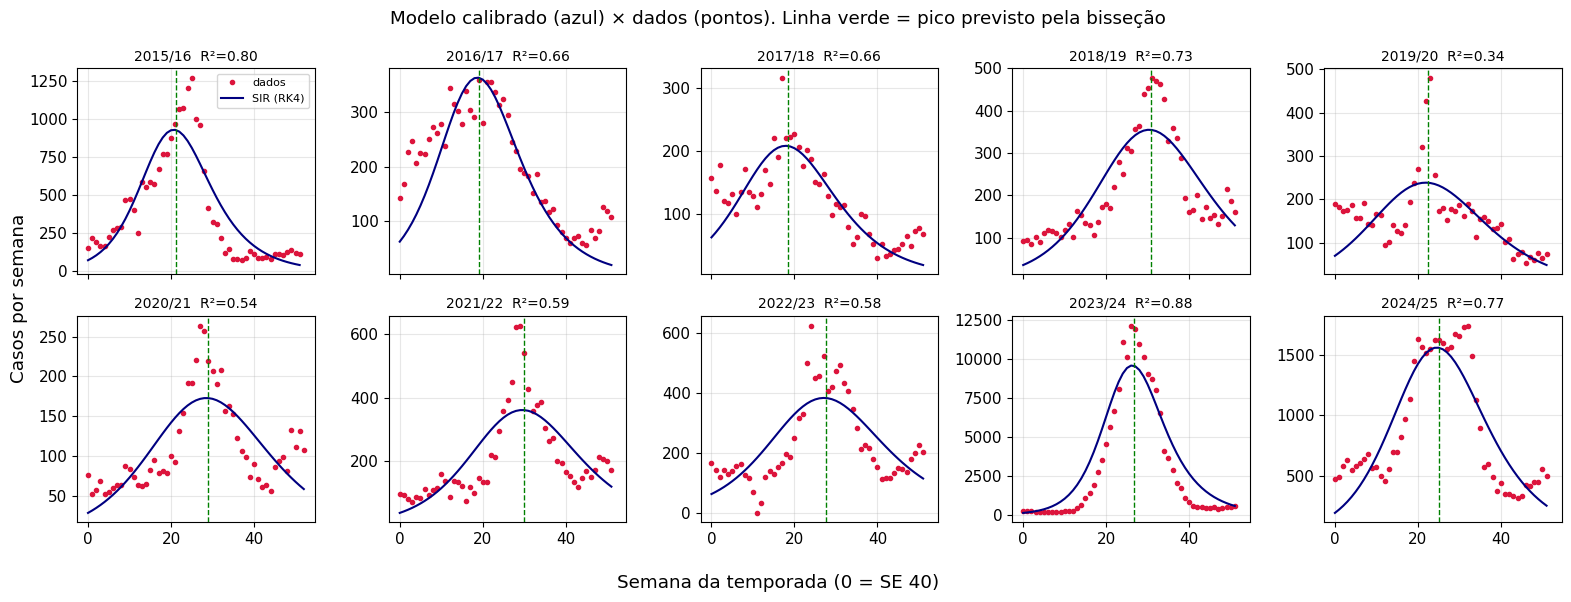

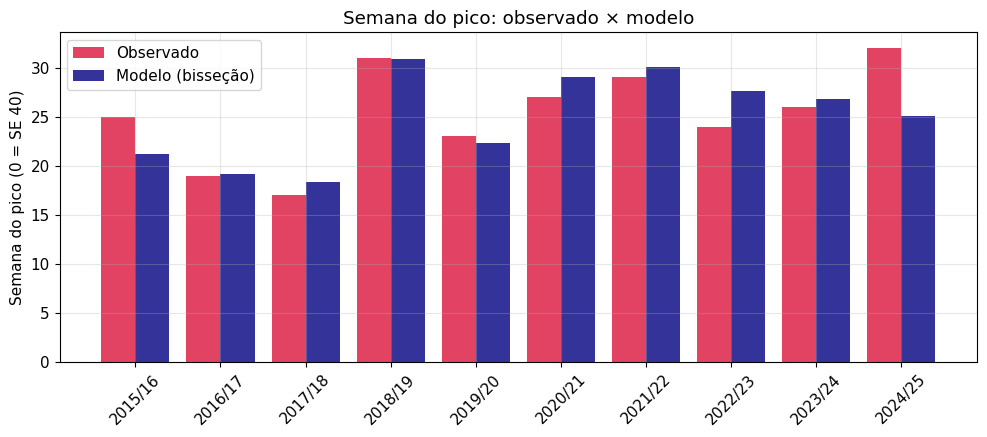

Erro absoluto médio do pico: 2.0 semanas
 gamma (1/sem)  período infeccioso (sem)  R2 médio  erro médio do pico (sem)
          0.25                       4.0      0.65                       2.1
          0.50                       2.0      0.64                       2.1
          1.00                       1.0      0.53                       3.7


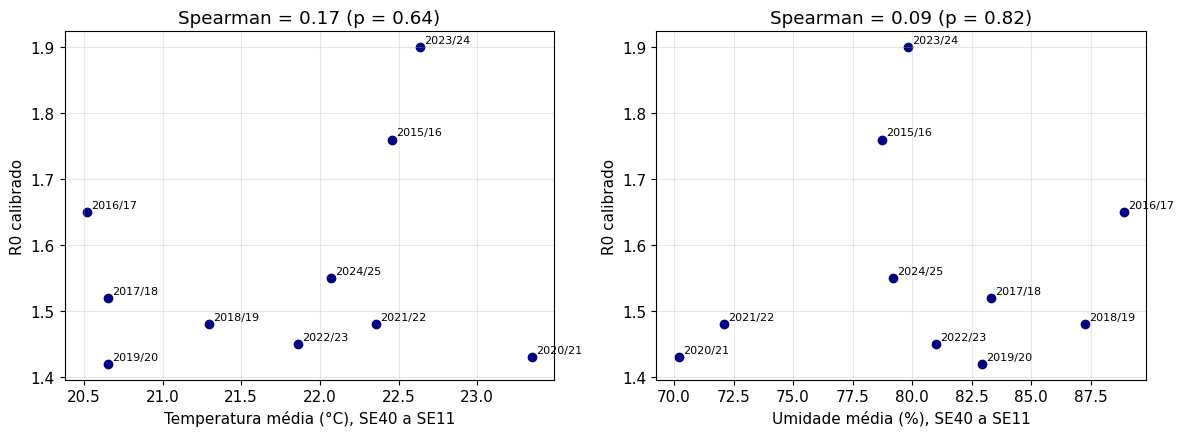

Temporada 2023/24: pico previsto na semana 26.8; pico sem ação = 9,560 casos/semana; total sem ação = 189,176 casos

 agir (sem. antes do pico)  semana da ação  redução do pico (%)  redução do total (%)
                        16            10.8                 52.2                  30.8
                        12            14.8                 49.5                  27.1
                         8            18.8                 43.6                  23.2
                         4            22.8                 22.1                  18.6
                         0            26.8                  1.7                  13.5


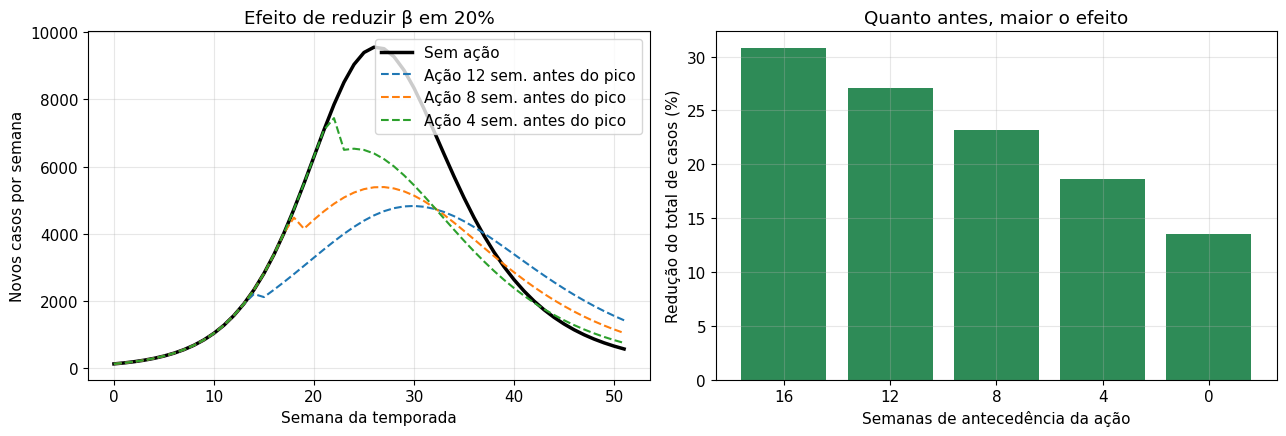

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import spearmanr

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

CAMINHO_CSV = "dengue_1-53.csv"
SE_INICIO_TEMPORADA = 40
H_PASSO = 0.25
H_FINO = 0.05
TOL_BISSECAO = 1e-4
MAX_IT_BISSECAO = 100
GAMMA_FIXO = 0.25
REDUCAO_BETA = 0.20
TEMPORADA_DEMO = "2023/24"

URL_API = ("https://info.dengue.mat.br/api/alertcity?geocode=3549904&disease=dengue"
           "&format=csv&ew_start=1&ew_end=53&ey_start=2015&ey_end=2025")
try:
    df = pd.read_csv(CAMINHO_CSV)
    print("Lido do arquivo:", CAMINHO_CSV)
except FileNotFoundError:
    df = pd.read_csv(URL_API)
    print("Arquivo não encontrado: dados baixados da API.")

df["data_iniSE"] = pd.to_datetime(df["data_iniSE"])
df = df.sort_values("data_iniSE").reset_index(drop=True)
df["ano"] = df["SE"] // 100
df["se"] = df["SE"] % 100

df = df[["data_iniSE", "SE", "ano", "se", "casos_est", "casos", "Rt", "pop",
         "tempmed", "tempmin", "tempmax", "umidmed", "umidmin", "umidmax"]]

clima = ["tempmed", "tempmin", "tempmax", "umidmed", "umidmin", "umidmax"]
print("Semanas sem clima, interpoladas:", int(df["tempmed"].isna().sum()))
df[clima] = df[clima].interpolate(limit_direction="both")

print(f"{len(df)} semanas, de {df.data_iniSE.min().date()} a {df.data_iniSE.max().date()}")
print(df.tail(3).to_string())

def montar_temporadas(df):
    temporadas = {}
    for ano in range(df.ano.min(), df.ano.max()):
        ini = df[(df.ano == ano) & (df.se == SE_INICIO_TEMPORADA)].data_iniSE
        fim = df[(df.ano == ano + 1) & (df.se == SE_INICIO_TEMPORADA)].data_iniSE
        if ini.empty or fim.empty:
            continue
        t = df[(df.data_iniSE >= ini.iloc[0]) & (df.data_iniSE < fim.iloc[0])].reset_index(drop=True)
        t["sem"] = np.arange(len(t))
        temporadas[f"{ano}/{str(ano + 1)[2:]}"] = t
    return temporadas

temporadas = montar_temporadas(df)
print({nome: len(t) for nome, t in temporadas.items()})

linhas = []
for nome, t in temporadas.items():
    i = t["casos_est"].idxmax()
    linhas.append({"temporada": nome, "SE_pico": int(t.se[i]), "data_pico": t.data_iniSE[i].date(),
                   "sem_pico": int(t["sem"][i]), "casos_no_pico": int(t.casos_est[i]),
                   "total_casos": int(t.casos_est.sum()),
                   "temp_no_pico": round(t.tempmed[i], 1), "umid_no_pico": round(t.umidmed[i], 1)})
tab_picos = pd.DataFrame(linhas)
print(tab_picos.to_string(index=False))
print(f"\nMediana da semana do pico: SE {int(tab_picos.SE_pico.median())}  |  "
      f"intervalo: SE {tab_picos.SE_pico.min()} a SE {tab_picos.SE_pico.max()}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
ticks, rotulos = [0, 13, 26, 39, 52], ["SE40\n(out)", "SE1\n(jan)", "SE14\n(abr)", "SE27\n(jul)", "SE40\n(out)"]
for nome, t in temporadas.items():
    destaque = (nome == TEMPORADA_DEMO)
    kw = dict(lw=2.8 if destaque else 1, alpha=1 if destaque else 0.6, label=nome)
    axs[0].plot(t["sem"], t.casos_est, **kw)
    axs[1].plot(t["sem"], t.casos_est / t.casos_est.max(), **kw)
axs[0].set_yscale("log")
axs[0].set_title("Casos por semana (escala log)")
axs[1].set_title("Cada temporada dividida pelo seu pico (compara o TIMING)")
for ax in axs:
    ax.set_xticks(ticks); ax.set_xticklabels(rotulos); ax.set_xlabel("Semana da temporada")
axs[0].set_ylabel("Casos estimados"); axs[1].set_ylabel("Fração do pico")
axs[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

mes = df.groupby(df.data_iniSE.dt.month).agg(casos=("casos_est", "median"),
                                              temp=("tempmed", "mean"), umid=("umidmed", "mean"))
nomes_mes = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, ax = plt.subplots()
ax.bar(nomes_mes, mes.casos, color="crimson", alpha=0.7)
ax.set_ylabel("Mediana de casos por semana", color="crimson")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(nomes_mes, mes.temp, "o-", color="orange"); ax2.set_ylabel("Temperatura média (°C)", color="orange")
ax.set_title("Sazonalidade: casos (barras) e temperatura (linha), 2015-2025")
plt.tight_layout(); plt.show()
print("Mês mais quente:", nomes_mes[mes.temp.idxmax() - 1], "| mês com maior mediana de casos:", nomes_mes[mes.casos.idxmax() - 1])

df["log_casos"] = np.log1p(df["casos_est"])
variaveis = ["tempmed", "umidmed"]
defasagens = range(0, 17)

corr = {v: [spearmanr(df[v].shift(l), df["log_casos"], nan_policy="omit")[0] for l in defasagens]
        for v in variaveis}

fig, ax = plt.subplots()
for v, c in corr.items():
    ax.plot(list(defasagens), c, "o-", label=v)
    print(f"{v}: maior correlação = {max(c):.2f} com defasagem de {int(np.argmax(c))} semanas")
ax.set_xlabel("Defasagem do clima (semanas antes)"); ax.set_ylabel("Correlação de Spearman")
ax.set_title("Quanto o clima de l semanas atrás se relaciona com os casos de hoje"); ax.legend()
plt.tight_layout(); plt.show()

melhor = int(np.argmax(corr["tempmed"]))
JANELA = (max(0, melhor - 1), melhor + 1)
print(f"Janela: de {JANELA[0]} a {JANELA[1]} semanas antes do pico\n")
linhas = []
for nome, t in temporadas.items():
    i = int(t["casos_est"].idxmax())
    j = t.loc[max(0, i - JANELA[1]): max(0, i - JANELA[0])]
    linhas.append({"temporada": nome,
                   "temp_pre_pico": round(j.tempmed.mean(), 1), "umid_pre_pico": round(j.umidmed.mean(), 1),
                   "temp_temporada": round(t.tempmed.mean(), 1), "umid_temporada": round(t.umidmed.mean(), 1)})
tab_clima = pd.DataFrame(linhas)
print(tab_clima.to_string(index=False))
print("\nMédia (10 temporadas):\n", tab_clima.drop(columns="temporada").mean().round(1).to_string())

def sir_rhs(y, t, beta_fun, gamma, N):
    S, I, R = y
    b = beta_fun(t)
    return np.array([-b * S * I / N,
                      b * S * I / N - gamma * I,
                      gamma * I])

def euler(y0, beta_fun, gamma, N, T, h):
    n = int(round(T / h))
    t = np.arange(n + 1) * h
    Y = np.zeros((n + 1, 3)); Y[0] = y0
    for k in range(n):
        Y[k + 1] = Y[k] + h * sir_rhs(Y[k], t[k], beta_fun, gamma, N)
    return t, Y

def rk4(y0, beta_fun, gamma, N, T, h):

    n = int(round(T / h))
    t = np.arange(n + 1) * h
    Y = np.zeros((n + 1, 3)); Y[0] = y0
    for k in range(n):
        y, tk = Y[k], t[k]
        k1 = sir_rhs(y,              tk,         beta_fun, gamma, N)
        k2 = sir_rhs(y + h / 2 * k1, tk + h / 2, beta_fun, gamma, N)
        k3 = sir_rhs(y + h / 2 * k2, tk + h / 2, beta_fun, gamma, N)
        k4 = sir_rhs(y + h * k3,     tk + h,     beta_fun, gamma, N)
        Y[k + 1] = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, Y

beta_t, gamma_t, N_t, I0_t, T_t = 1.2, 0.7, 1e5, 10.0, 20
y0_t = [N_t - I0_t, I0_t, 0.0]
bf = lambda t: beta_t

H_REF = 1 / 512
_, Yref = rk4(y0_t, bf, gamma_t, N_t, T_t, H_REF)
I_ref = Yref[::512, 1]

hs = [1, 0.5, 0.25, 0.125]
err_eu, err_rk = [], []
for h in hs:
    k = int(round(1 / h))
    _, Ye = euler(y0_t, bf, gamma_t, N_t, T_t, h)
    _, Yr = rk4(y0_t, bf, gamma_t, N_t, T_t, h)
    err_eu.append(np.max(np.abs(Ye[::k, 1] - I_ref)))
    err_rk.append(np.max(np.abs(Yr[::k, 1] - I_ref)))

ordem_eu = np.polyfit(np.log(hs), np.log(err_eu), 1)[0]
ordem_rk = np.polyfit(np.log(hs), np.log(err_rk), 1)[0]
print(f"{'h':>7} {'erro Euler':>14} {'erro RK4':>14}")
for h, a, b in zip(hs, err_eu, err_rk):
    print(f"{h:>7} {a:>14.4g} {b:>14.4g}")
print(f"\nOrdem estimada: Euler ≈ {ordem_eu:.2f} (teórica 1)  |  RK4 ≈ {ordem_rk:.2f} (teórica 4)")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].loglog(hs, err_eu, "o-", label="Euler"); axs[0].loglog(hs, err_rk, "s-", label="RK4")
axs[0].set_xlabel("passo h (semanas)"); axs[0].set_ylabel("erro máximo em I(t)")
axs[0].set_title("Erro × passo (log-log)"); axs[0].legend()
_, Ye1 = euler(y0_t, bf, gamma_t, N_t, T_t, 1); _, Yr1 = rk4(y0_t, bf, gamma_t, N_t, T_t, 1)
axs[1].plot(range(T_t + 1), I_ref, "k-", lw=2.5, label="Referência (RK4, h=1/512)")
axs[1].plot(range(T_t + 1), Ye1[:, 1], "o--", label="Euler h=1")
axs[1].plot(range(T_t + 1), Yr1[:, 1], "s--", label="RK4 h=1")
axs[1].set_xlabel("semana"); axs[1].set_ylabel("Infectados I(t)"); axs[1].set_title("Mesmo passo (h = 1 semana)"); axs[1].legend()
plt.tight_layout(); plt.show()

def novos_casos_modelo(beta, gamma, rho, pop, I0, n_sem, h=H_PASSO):
    N_ef = rho * pop
    y0 = [N_ef - I0, I0, 0.0]
    _, Y = rk4(y0, lambda t: beta, gamma, N_ef, n_sem, h)
    S_sem = Y[::int(round(1 / h)), 0]
    return -np.diff(S_sem)

def calibrar(t, gamma=GAMMA_FIXO):
    obs = t["casos_est"].to_numpy(float)
    n, pop, I0 = len(obs), float(t["pop"].iloc[0]), max(obs[0], 1.0)
    f = lambda sem, beta, rho: novos_casos_modelo(beta, gamma, rho, pop, I0, n)
    melhor = None
    for chute in [(1.5 * gamma, 0.1), (1.2 * gamma, 0.02)]:
        try:
            popt, _ = curve_fit(f, np.arange(n), obs, p0=chute, bounds=([0.02, 0.001], [10, 1]), maxfev=5000)
        except RuntimeError:
            continue
        sse = np.sum((obs - f(None, *popt)) ** 2)
        if melhor is None or sse < melhor[0]:
            melhor = (sse, popt)
    sse, (beta, rho) = melhor
    sim = f(None, beta, rho)
    r2 = 1 - sse / np.sum((obs - obs.mean()) ** 2)
    return dict(beta=beta, gamma=gamma, rho=rho, R0=beta / gamma, r2=r2,
                sim=sim, obs=obs, pop=pop, I0=I0, n=n)

def trapezio(y, x):
    return np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2)

def retangulo(y, x):
    return np.sum((x[1:] - x[:-1]) * y[:-1])

T_int = 20
t_f, Y_f = rk4(y0_t, bf, gamma_t, N_t, T_int, H_FINO)
taxa = beta_t * Y_f[:, 0] * Y_f[:, 1] / N_t
exato = Y_f[0, 0] - Y_f[-1, 0]
print(f"Total exato S(0)-S(T) = {exato:,.1f}\n")
print(f"{'h':>6} {'retângulo':>14} {'erro':>10} {'trapézio':>14} {'erro':>10}")
for h in [1, 0.5, 0.25]:
    k = int(round(h / H_FINO))
    tr, ya = t_f[::k], taxa[::k]
    a, b = retangulo(ya, tr), trapezio(ya, tr)
    print(f"{h:>6} {a:>14,.1f} {abs(a-exato):>10.2f} {b:>14,.1f} {abs(b-exato):>10.2f}")

def semana_do_pico(beta, gamma, N_ef, y0, T):
    t, Y = rk4(y0, lambda tt: beta, gamma, N_ef, T, H_FINO)
    S, I = Y[:, 0], Y[:, 1]
    f = lambda tt: beta * (np.interp(tt, t, S) - np.interp(tt, t, I)) / N_ef - gamma
    a, b = 0.0, t[np.argmax(I)]
    if f(a) <= 0:  return 0.0, 0
    if f(b) > 0:   return np.nan, 0
    it = 0
    while (b - a) > TOL_BISSECAO and it < MAX_IT_BISSECAO:
        m = (a + b) / 2
        if f(a) * f(m) <= 0: b = m
        else:                a = m
        it += 1
    return (a + b) / 2, it

sem_b, it_b = semana_do_pico(beta_t, gamma_t, N_t, y0_t, 30)
_, Yt = rk4(y0_t, bf, gamma_t, N_t, 30, H_FINO)
sem_max = np.argmax(beta_t * Yt[:, 0] * Yt[:, 1] / N_t) * H_FINO
print(f"Bisseção: pico em t = {sem_b:.3f} semanas ({it_b} iterações)  |  máximo direto na malha: {sem_max:.2f} semanas")

resultados = {}
for nome, t in temporadas.items():
    r = calibrar(t)
    N_ef = r["rho"] * r["pop"]
    y0 = [N_ef - r["I0"], r["I0"], 0.0]
    r["sem_pico_mod"], r["it_bissecao"] = semana_do_pico(r["beta"], r["gamma"], N_ef, y0, r["n"])
    r["sem_pico_obs"] = int(np.argmax(r["obs"]))
    resultados[nome] = r

tab = pd.DataFrame({
    "beta": {k: v["beta"] for k, v in resultados.items()},
    "gamma": {k: v["gamma"] for k, v in resultados.items()},
    "rho": {k: v["rho"] for k, v in resultados.items()},
    "R0": {k: v["R0"] for k, v in resultados.items()},
    "R2": {k: v["r2"] for k, v in resultados.items()},
    "pico_obs (sem)": {k: v["sem_pico_obs"] for k, v in resultados.items()},
    "pico_modelo (sem)": {k: v["sem_pico_mod"] for k, v in resultados.items()},
    "total_obs": {k: v["obs"].sum() for k, v in resultados.items()},
    "total_modelo": {k: v["sim"].sum() for k, v in resultados.items()},
}).round(2)
tab["erro_pico (sem)"] = (tab["pico_modelo (sem)"] - tab["pico_obs (sem)"]).round(1)
print(tab.to_string())

nomes = list(resultados)
fig, axs = plt.subplots(2, 5, figsize=(16, 6), sharex=True)
for ax, nome in zip(axs.ravel(), nomes):
    r = resultados[nome]
    ax.plot(r["obs"], "o", ms=3, color="crimson", label="dados")
    ax.plot(r["sim"], "-", color="navy", label="SIR (RK4)")
    ax.axvline(r["sem_pico_mod"], color="green", ls="--", lw=1)
    ax.set_title(f"{nome}  R²={r['r2']:.2f}", fontsize=10)
axs[0, 0].legend(fontsize=8)
fig.supxlabel("Semana da temporada (0 = SE 40)"); fig.supylabel("Casos por semana")
fig.suptitle("Modelo calibrado (azul) × dados (pontos). Linha verde = pico previsto pela bisseção")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(nomes))
ax.bar(x - 0.2, tab["pico_obs (sem)"], 0.4, label="Observado", color="crimson", alpha=0.8)
ax.bar(x + 0.2, tab["pico_modelo (sem)"], 0.4, label="Modelo (bisseção)", color="navy", alpha=0.8)
ax.set_xticks(x); ax.set_xticklabels(nomes, rotation=45)
ax.set_ylabel("Semana do pico (0 = SE 40)"); ax.set_title("Semana do pico: observado × modelo"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Erro absoluto médio do pico: {tab['erro_pico (sem)'].abs().mean():.1f} semanas")

gammas_teste = [0.25, 0.5, 1.0]
linhas = []
for g in gammas_teste:
    r2s, erros = [], []
    for nome, t in temporadas.items():
        r = calibrar(t, gamma=g)
        N_ef = r["rho"] * r["pop"]
        sem_mod, _ = semana_do_pico(r["beta"], g, N_ef, [N_ef - r["I0"], r["I0"], 0.0], r["n"])
        r2s.append(r["r2"]); erros.append(abs(sem_mod - np.argmax(r["obs"])))
    linhas.append({"gamma (1/sem)": g, "período infeccioso (sem)": round(1 / g, 1),
                   "R2 médio": round(np.mean(r2s), 2), "erro médio do pico (sem)": round(np.nanmean(erros), 1)})
print(pd.DataFrame(linhas).to_string(index=False))

clima_pv = pd.DataFrame({
    "temp": {n: temporadas[n].loc[:23, "tempmed"].mean() for n in nomes},
    "umid": {n: temporadas[n].loc[:23, "umidmed"].mean() for n in nomes}})

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, rot in zip(axs, ["temp", "umid"], ["Temperatura média (°C), SE40 a SE11", "Umidade média (%), SE40 a SE11"]):
    ax.scatter(clima_pv[col], tab["R0"], color="navy")
    for n in nomes:
        ax.annotate(n, (clima_pv.loc[n, col], tab.loc[n, "R0"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    rho_s, p = spearmanr(clima_pv[col], tab["R0"])
    ax.set_xlabel(rot); ax.set_ylabel("R0 calibrado"); ax.set_title(f"Spearman = {rho_s:.2f} (p = {p:.2f})")
plt.tight_layout(); plt.show()

def simular_cenario(r, t_int, reducao):
    N_ef = r["rho"] * r["pop"]
    y0 = [N_ef - r["I0"], r["I0"], 0.0]
    beta_fun = lambda t: r["beta"] if t < t_int else r["beta"] * (1 - reducao)
    _, Y = rk4(y0, beta_fun, r["gamma"], N_ef, r["n"], H_FINO)
    S_sem = Y[::int(round(1 / H_FINO)), 0]
    novos = -np.diff(S_sem)
    return novos, novos.max(), S_sem[0] - S_sem[-1]

r = resultados[TEMPORADA_DEMO]
t_pico = r["sem_pico_mod"]
base, pico_base, total_base = simular_cenario(r, t_int=1e9, reducao=0)

antecedencias = [16, 12, 8, 4, 0]
linhas, curvas = [], {}
for a in antecedencias:
    t_int = max(0.0, t_pico - a)
    novos, pico, total = simular_cenario(r, t_int, REDUCAO_BETA)
    curvas[a] = novos
    linhas.append({"agir (sem. antes do pico)": a, "semana da ação": round(t_int, 1),
                   "redução do pico (%)": round(100 * (1 - pico / pico_base), 1),
                   "redução do total (%)": round(100 * (1 - total / total_base), 1)})
tab_cen = pd.DataFrame(linhas)
print(f"Temporada {TEMPORADA_DEMO}: pico previsto na semana {t_pico:.1f}; "
      f"pico sem ação = {pico_base:,.0f} casos/semana; total sem ação = {total_base:,.0f} casos\n")
print(tab_cen.to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(base, "k-", lw=2.5, label="Sem ação")
for a in [12, 8, 4]:
    axs[0].plot(curvas[a], "--", label=f"Ação {a} sem. antes do pico")
axs[0].set_xlabel("Semana da temporada"); axs[0].set_ylabel("Novos casos por semana")
axs[0].set_title(f"Efeito de reduzir β em {REDUCAO_BETA*100:.0f}%"); axs[0].legend()
axs[1].bar([str(a) for a in antecedencias], tab_cen["redução do total (%)"], color="seagreen")
axs[1].set_xlabel("Semanas de antecedência da ação"); axs[1].set_ylabel("Redução do total de casos (%)")
axs[1].set_title("Quanto antes, maior o efeito")
plt.tight_layout(); plt.show()